**Name:** Sandeep Reddy Banda
**Course:** MSCS 634 – Advanced Big Data and Data Mining
**Lab Assignment:** Lab 6 – Association Rule Mining with Apriori and FP-Growth

---

# Lab 6: Association Rule Mining

In this lab I mine a real transactional dataset for frequent itemsets and association rules using two algorithms, Apriori and FP-Growth, and then compare them. I also use Seaborn to visualize what I find. The dataset I picked is the **Online Retail dataset** from the UCI Machine Learning Repository. It has every line item from invoices of a UK-based online gift shop, so each invoice can be treated as one "basket" of products.

Plan for the notebook:
1. Data preparation and exploration
2. Frequent itemsets with Apriori
3. Frequent itemsets with FP-Growth
4. Association rules (support, confidence, lift)
5. Comparing the two algorithms and reflecting on the lab

## Step 1: Data Preparation

### 1.1 Import libraries

In [1]:
import os
import time
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 150)

### 1.2 Load the dataset

I'm using the Online Retail dataset from UCI. The code below uses a local copy of `Online Retail.xlsx` if it is in the same folder as the notebook. If not, it downloads the zip file from UCI and extracts it.

In [2]:
FILE_NAME = "Online Retail.xlsx"
UCI_URL = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"

if not os.path.exists(FILE_NAME):
    print("Local file not found, downloading from UCI...")
    urllib.request.urlretrieve(UCI_URL, "online_retail.zip")
    with zipfile.ZipFile("online_retail.zip") as z:
        z.extractall(".")

raw = pd.read_excel(FILE_NAME)
print("Raw shape:", raw.shape)
raw.head()

Raw shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


The columns I care about are `InvoiceNo` (the basket id) and `Description` (the item name). `Quantity`, `Country`, and `UnitPrice` help with cleaning. Each row is one product on one invoice, which is already the item-level format Apriori and FP-Growth need once I reshape it.

### 1.3 Data cleaning

Looking at the raw data, these are the problems I need to deal with before mining:
- Some rows have no description, so I can't use them as items.
- Invoice numbers that start with "C" are cancellations, not purchases.
- Some rows have zero or negative quantities or prices (returns or adjustments).
- There are non-product rows such as postage, bank charges, and manual adjustments. These show up on a lot of invoices but they are not things customers actually shop for, so they would pollute the results.
- Descriptions have extra whitespace.
- The dataset has many countries. Most invoices are from the United Kingdom, so I keep only the UK to keep the baskets consistent and the data size manageable.

In [4]:
print("Missing values per column:")
print(raw.isnull().sum())

Missing values per column:


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [5]:
df = raw.copy()

# drop rows without a description or invoice number
df = df.dropna(subset=["InvoiceNo", "Description"])

# clean the text columns
df["InvoiceNo"] = df["InvoiceNo"].astype(str).str.strip()
df["Description"] = df["Description"].astype(str).str.strip().str.upper()

# remove cancelled invoices
df = df[~df["InvoiceNo"].str.startswith("C")]

# remove returns / bad rows
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]

# remove non-product rows
non_products = ["POSTAGE", "DOTCOM POSTAGE", "MANUAL", "BANK CHARGES", "CARRIAGE",
                "AMAZON FEE", "CRUK COMMISSION", "DISCOUNT", "SAMPLES",
                "ADJUST BAD DEBT", "ADJUSTMENT BY PETER ON JUNE25 2010"]
df = df[~df["Description"].isin(non_products)]

# keep only United Kingdom orders
df = df[df["Country"] == "United Kingdom"]

print("Shape after cleaning:", df.shape)
print("Unique invoices:", df["InvoiceNo"].nunique())
print("Unique items:", df["Description"].nunique())

Shape after cleaning: (484038, 8)
Unique invoices: 17901
Unique items: 3988


### 1.4 Build the basket (transaction) matrix

Apriori and FP-Growth from `mlxtend` need a one-hot encoded table where each row is an invoice, each column is an item, and the value is True/False for whether the item was in that invoice. I first drop duplicate item rows within an invoice so each item only counts once per basket.

In [6]:
baskets = df[["InvoiceNo", "Description"]].drop_duplicates()

# numeric codes for each invoice and each item, then fill a True/False matrix directly
# (pivot_table on this much data used too much memory and crashed my kernel)
inv_codes, inv_names = pd.factorize(baskets["InvoiceNo"])
item_codes, item_names = pd.factorize(baskets["Description"])

matrix = np.zeros((len(inv_names), len(item_names)), dtype=bool)
matrix[inv_codes, item_codes] = True

basket = pd.DataFrame(matrix, index=inv_names, columns=item_names)
basket = basket.reindex(sorted(basket.columns), axis=1)

# free the big intermediate tables, I don't need them anymore
del raw, df, baskets, matrix
import gc; gc.collect()

print("Basket matrix shape (invoices x items):", basket.shape)
print("Average items per invoice:", round(basket.sum(axis=1).mean(), 2))

Basket matrix shape (invoices x items): (17901, 3988)
Average items per invoice: 26.45


Before mining, I also look at how big the baskets are, since this tells me a lot about how hard the mining will be.

count    17901.000000
mean        26.450254
std         48.827043
min          1.000000
25%          6.000000
50%         15.000000
75%         29.000000
max       1107.000000
dtype: float64


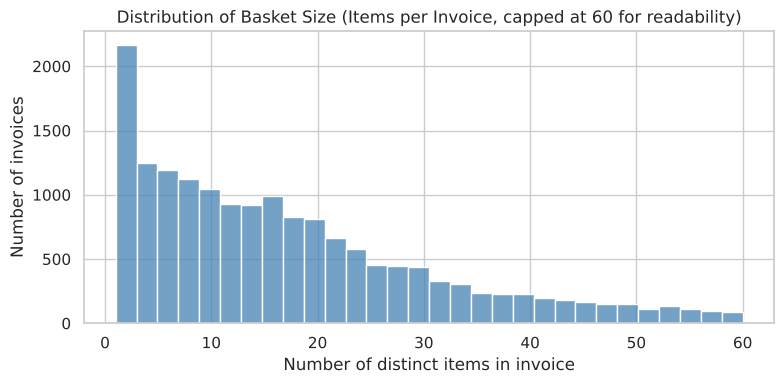

In [7]:
basket_sizes = basket.sum(axis=1)
print(basket_sizes.describe())

plt.figure(figsize=(8, 4))
sns.histplot(basket_sizes[basket_sizes <= 60], bins=30, color="steelblue")
plt.title("Distribution of Basket Size (Items per Invoice, capped at 60 for readability)")
plt.xlabel("Number of distinct items in invoice")
plt.ylabel("Number of invoices")
plt.tight_layout()
plt.show()

### 1.5 Exploring the data with visualizations

**Most frequently occurring items.** This barplot shows the 15 items that show up in the most invoices.

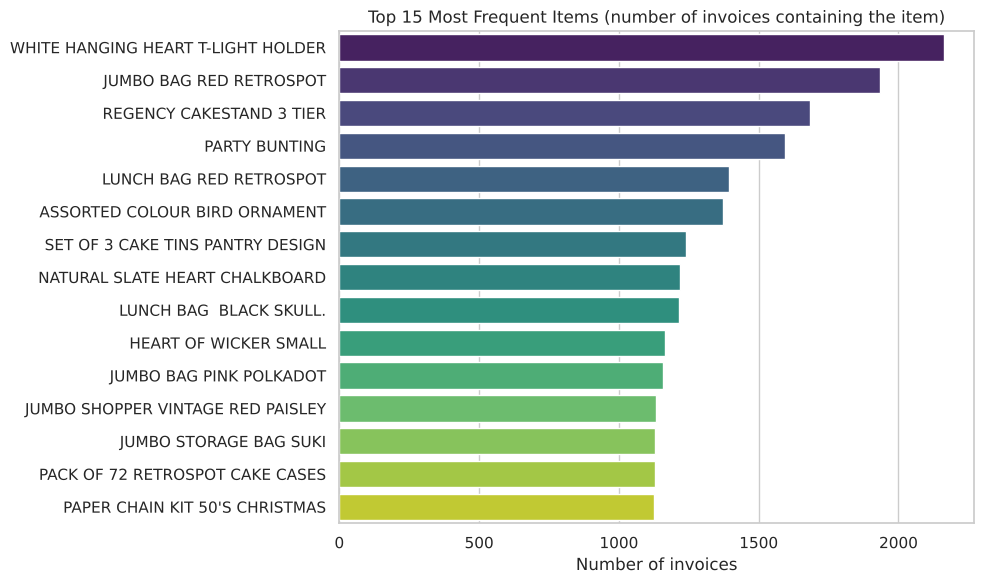

In [8]:
item_counts = basket.sum().sort_values(ascending=False)
top_items = item_counts.head(15).reset_index()
top_items.columns = ["Item", "Invoices"]

plt.figure(figsize=(10, 6))
sns.barplot(data=top_items, y="Item", x="Invoices", hue="Item", palette="viridis", legend=False)
plt.title("Top 15 Most Frequent Items (number of invoices containing the item)")
plt.xlabel("Number of invoices")
plt.ylabel("")
plt.tight_layout()
plt.show()

**Item co-occurrence heatmap.** To see which items tend to be bought together, I count how many invoices contain each pair of the top 12 items. The diagonal is just how often the item appears by itself, so I mask it out to make the pairs easier to read.

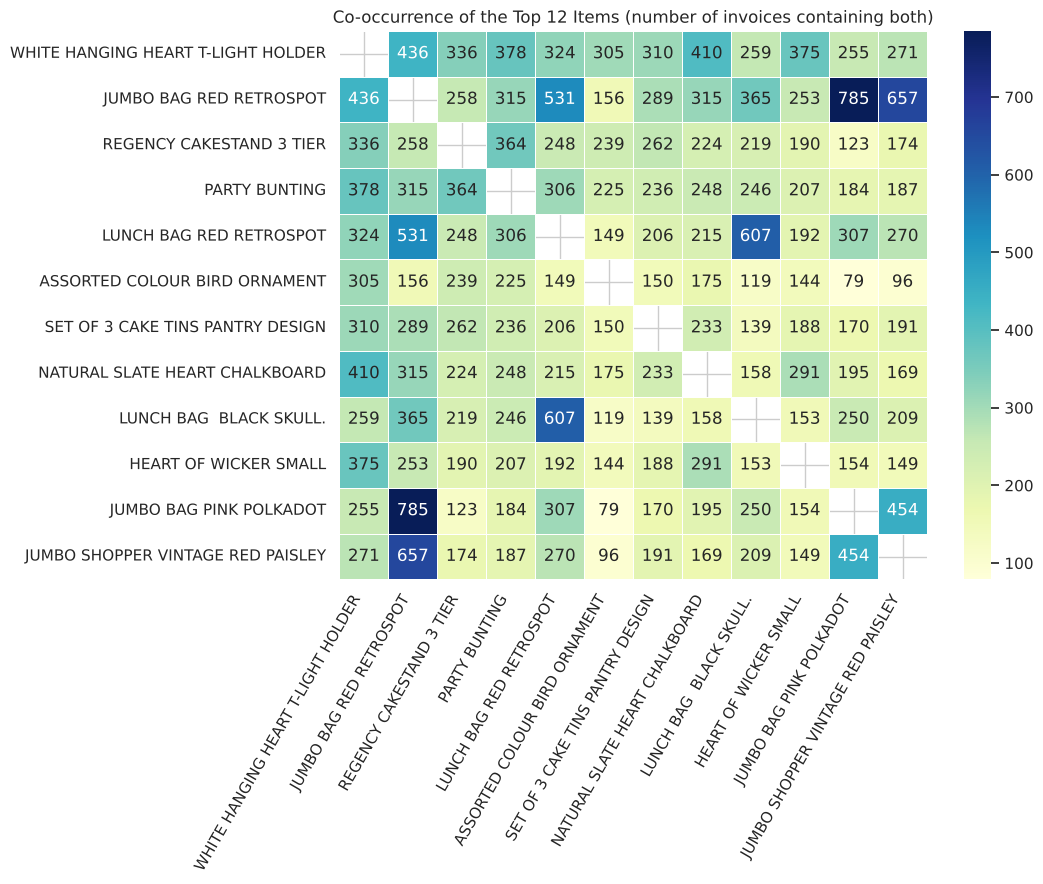

In [9]:
top12 = item_counts.head(12).index
sub = basket[top12].astype(int)
cooc = sub.T.dot(sub)

mask = np.eye(len(cooc), dtype=bool)

plt.figure(figsize=(11, 9))
sns.heatmap(cooc, mask=mask, annot=True, fmt="d", cmap="YlGnBu", linewidths=0.5)
plt.title("Co-occurrence of the Top 12 Items (number of invoices containing both)")
plt.xlabel("")
plt.ylabel("")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

**What I noticed:** The item frequencies drop off fast, so a few popular products show up in a lot of invoices and there is a very long tail of items that are rarely bought. This is important for choosing the support threshold in the next step. The heatmap also shows that some pairs of items show up together much more than others, which gives a first hint about what the rules will look like.

## Step 2: Frequent Itemset Mining Using Apriori

### Choosing the support threshold

Because there are thousands of different items and only a small number of them are common, a high support value would return almost nothing, but a very low one would make the algorithm slow and give a huge number of itemsets. I started from a support of 0.02, meaning an itemset has to show up in at least 2% of invoices, and this gave me a good number of itemsets to work with. I will use the same value for FP-Growth so the comparison is fair.

In [10]:
MIN_SUPPORT = 0.02

# An item that appears in fewer invoices than the support threshold can never be part of a
# frequent itemset, so I drop those columns first. This does not change the results, it just
# keeps the matrix small enough for my computer's memory (the full matrix crashed my kernel).
item_support = basket.mean()
basket_mining = basket.loc[:, item_support >= MIN_SUPPORT]
print(f"Items kept for mining: {basket_mining.shape[1]} out of {basket.shape[1]}")

start = time.perf_counter()
apriori_itemsets = apriori(basket_mining, min_support=MIN_SUPPORT, use_colnames=True)
apriori_time = time.perf_counter() - start

apriori_itemsets["length"] = apriori_itemsets["itemsets"].apply(len)
apriori_itemsets = apriori_itemsets.sort_values("support", ascending=False).reset_index(drop=True)

print(f"Apriori found {len(apriori_itemsets)} frequent itemsets in {apriori_time:.2f} seconds")
print("Itemsets by size:")
print(apriori_itemsets["length"].value_counts().sort_index())

Items kept for mining: 300 out of 3988


Apriori found 399 frequent itemsets in 1.46 seconds
Itemsets by size:
length
1    300
2     94
3      5
Name: count, dtype: int64


Here are the frequent itemsets with their support values (top 20 by support):

In [11]:
def itemset_label(s):
    return " + ".join(sorted(s))

display_df = apriori_itemsets.copy()
display_df["itemsets"] = display_df["itemsets"].apply(itemset_label)
display_df.head(20)

,support,itemsets,length
0,0.120775,WHITE HANGING HEART T-LIGHT HOLDER,1
1,0.108095,JUMBO BAG RED RETROSPOT,1
2,0.094129,REGENCY CAKESTAND 3 TIER,1
3,0.088989,PARTY BUNTING,1
4,0.077761,LUNCH BAG RED RETROSPOT,1
5,0.076588,ASSORTED COLOUR BIRD ORNAMENT,1
6,0.069326,SET OF 3 CAKE TINS PANTRY DESIGN,1
7,0.068097,NATURAL SLATE HEART CHALKBOARD,1
8,0.067929,LUNCH BAG BLACK SKULL.,1
9,0.065024,HEART OF WICKER SMALL,1


**Top 15 frequent itemsets from Apriori:**

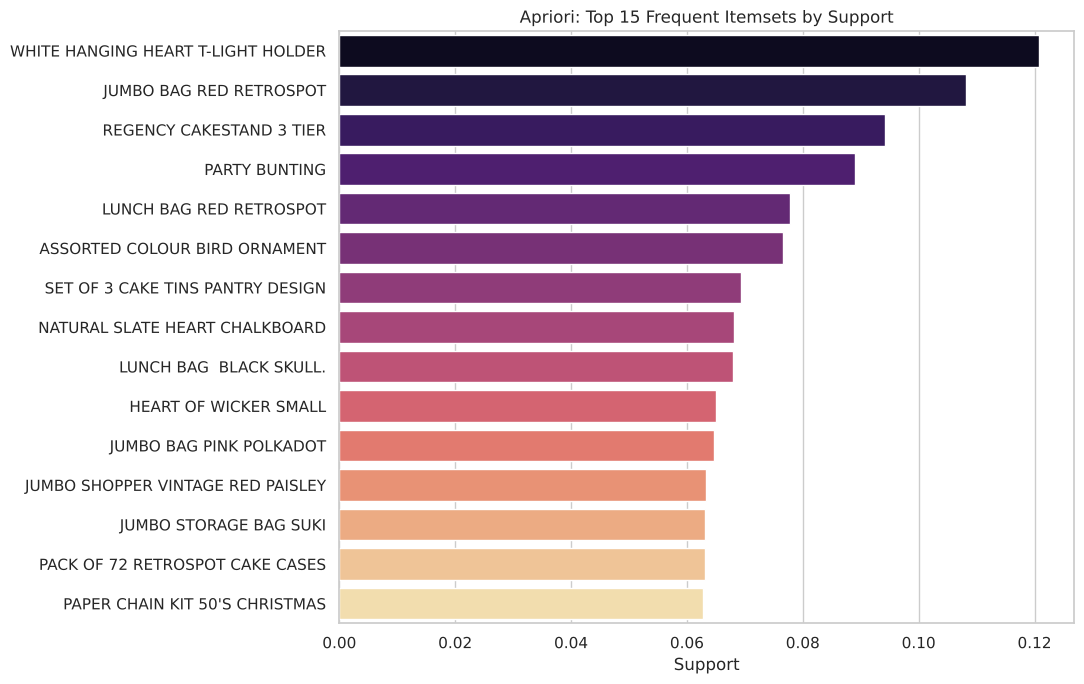

In [12]:
top_apriori = apriori_itemsets.head(15).copy()
top_apriori["label"] = top_apriori["itemsets"].apply(itemset_label)

plt.figure(figsize=(11, 7))
sns.barplot(data=top_apriori, y="label", x="support", hue="label", palette="magma", legend=False)
plt.title("Apriori: Top 15 Frequent Itemsets by Support")
plt.xlabel("Support")
plt.ylabel("")
plt.tight_layout()
plt.show()

The single items take up most of the top spots since a single item will always be at least as frequent as any itemset that contains it. The more interesting patterns are the itemsets with 2 or more items, so I look at those separately below.

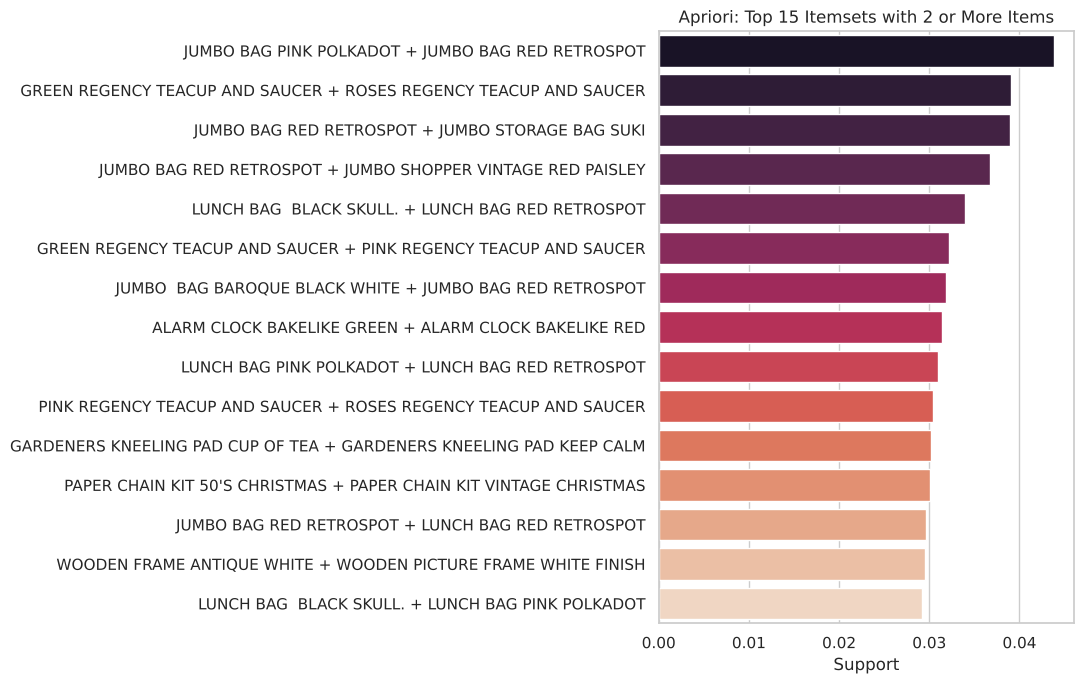

In [13]:
multi_apriori = apriori_itemsets[apriori_itemsets["length"] >= 2].head(15).copy()
multi_apriori["label"] = multi_apriori["itemsets"].apply(itemset_label)

plt.figure(figsize=(11, 7))
sns.barplot(data=multi_apriori, y="label", x="support", hue="label", palette="rocket", legend=False)
plt.title("Apriori: Top 15 Itemsets with 2 or More Items")
plt.xlabel("Support")
plt.ylabel("")
plt.tight_layout()
plt.show()

## Step 3: Frequent Itemset Mining Using FP-Growth

Now I run FP-Growth on the exact same basket matrix and the same `min_support` of 0.02.

In [14]:
start = time.perf_counter()
fp_itemsets = fpgrowth(basket_mining, min_support=MIN_SUPPORT, use_colnames=True)
fp_time = time.perf_counter() - start

fp_itemsets["length"] = fp_itemsets["itemsets"].apply(len)
fp_itemsets = fp_itemsets.sort_values("support", ascending=False).reset_index(drop=True)

print(f"FP-Growth found {len(fp_itemsets)} frequent itemsets in {fp_time:.2f} seconds")
print("Itemsets by size:")
print(fp_itemsets["length"].value_counts().sort_index())

FP-Growth found 399 frequent itemsets in 1.62 seconds
Itemsets by size:
length
1    300
2     94
3      5
Name: count, dtype: int64


In [15]:
fp_display = fp_itemsets.copy()
fp_display["itemsets"] = fp_display["itemsets"].apply(itemset_label)
fp_display.head(20)

,support,itemsets,length
0,0.120775,WHITE HANGING HEART T-LIGHT HOLDER,1
1,0.108095,JUMBO BAG RED RETROSPOT,1
2,0.094129,REGENCY CAKESTAND 3 TIER,1
3,0.088989,PARTY BUNTING,1
4,0.077761,LUNCH BAG RED RETROSPOT,1
5,0.076588,ASSORTED COLOUR BIRD ORNAMENT,1
6,0.069326,SET OF 3 CAKE TINS PANTRY DESIGN,1
7,0.068097,NATURAL SLATE HEART CHALKBOARD,1
8,0.067929,LUNCH BAG BLACK SKULL.,1
9,0.065024,HEART OF WICKER SMALL,1


### 3.1 Do the two algorithms give the same output?

Both algorithms are supposed to find exactly the same frequent itemsets, since they only differ in how they search. I check that by comparing the itemsets and their support values.

In [16]:
a = {frozenset(s): round(sup, 6) for s, sup in zip(apriori_itemsets["itemsets"], apriori_itemsets["support"])}
f = {frozenset(s): round(sup, 6) for s, sup in zip(fp_itemsets["itemsets"], fp_itemsets["support"])}

print("Same number of itemsets:", len(a) == len(f))
print("Exactly the same itemsets and supports:", a == f)

Same number of itemsets: True
Exactly the same itemsets and supports: True


**Top 15 frequent itemsets with 2 or more items from FP-Growth:**

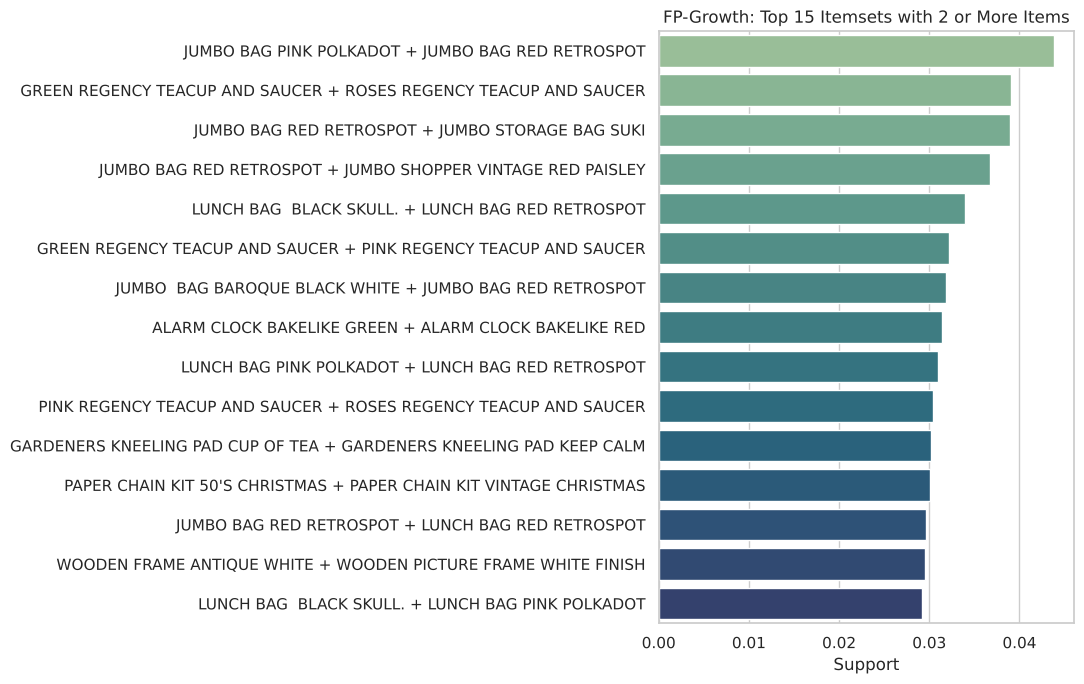

In [17]:
multi_fp = fp_itemsets[fp_itemsets["length"] >= 2].head(15).copy()
multi_fp["label"] = multi_fp["itemsets"].apply(itemset_label)

plt.figure(figsize=(11, 7))
sns.barplot(data=multi_fp, y="label", x="support", hue="label", palette="crest", legend=False)
plt.title("FP-Growth: Top 15 Itemsets with 2 or More Items")
plt.xlabel("Support")
plt.ylabel("")
plt.tight_layout()
plt.show()

### 3.2 Efficiency comparison

A single timing can be affected by whatever else is running on my computer, so I ran each algorithm 5 times and took the average.

In [18]:
def time_algo(func, runs=5):
    times = []
    for _ in range(runs):
        t0 = time.perf_counter()
        func(basket_mining, min_support=MIN_SUPPORT, use_colnames=True)
        times.append(time.perf_counter() - t0)
    return times

apriori_times = time_algo(apriori)
fp_times = time_algo(fpgrowth)

timing = pd.DataFrame({
    "Algorithm": ["Apriori", "FP-Growth"],
    "Avg time (s)": [np.mean(apriori_times), np.mean(fp_times)],
    "Min time (s)": [np.min(apriori_times), np.min(fp_times)],
    "Max time (s)": [np.max(apriori_times), np.max(fp_times)],
    "Itemsets found": [len(apriori_itemsets), len(fp_itemsets)],
})
timing = timing.round(3)
timing

,Algorithm,Avg time (s),Min time (s),Max time (s),Itemsets found
0,Apriori,1.313,1.247,1.367,399
1,FP-Growth,1.835,1.587,2.047,399


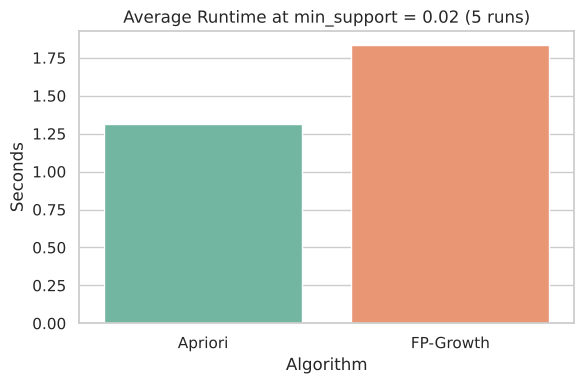

Apriori was about 1.4x faster than FP-Growth on this dataset.


In [19]:
plt.figure(figsize=(6, 4))
sns.barplot(data=timing, x="Algorithm", y="Avg time (s)", hue="Algorithm", palette="Set2", legend=False)
plt.title(f"Average Runtime at min_support = {MIN_SUPPORT} (5 runs)")
plt.ylabel("Seconds")
plt.tight_layout()
plt.show()

ratio = timing.loc[0, "Avg time (s)"] / timing.loc[1, "Avg time (s)"]
if ratio >= 1:
    print(f"FP-Growth was about {ratio:.1f}x faster than Apriori on this dataset.")
else:
    print(f"Apriori was about {1/ratio:.1f}x faster than FP-Growth on this dataset.")

I also wanted to see how the two algorithms behave as the support threshold gets smaller, because that is where the differences should show up the most.

In [20]:
supports = [0.05, 0.04, 0.03, 0.025, 0.02]
rows = []
for s in supports:
    sub_basket = basket.loc[:, item_support >= s]   # prune items for this threshold
    t0 = time.perf_counter()
    ap = apriori(sub_basket, min_support=s, use_colnames=True)
    t_ap = time.perf_counter() - t0

    t0 = time.perf_counter()
    fp = fpgrowth(sub_basket, min_support=s, use_colnames=True)
    t_fp = time.perf_counter() - t0

    rows.append({"min_support": s, "Apriori (s)": t_ap, "FP-Growth (s)": t_fp, "Itemsets": len(fp)})

sweep = pd.DataFrame(rows).round(3)
sweep

,min_support,Apriori (s),FP-Growth (s),Itemsets
0,0.050,0.015,0.385,35
1,0.040,0.066,0.272,66
2,0.030,0.261,0.508,146
3,0.025,0.669,0.991,238
4,0.020,1.429,1.783,399


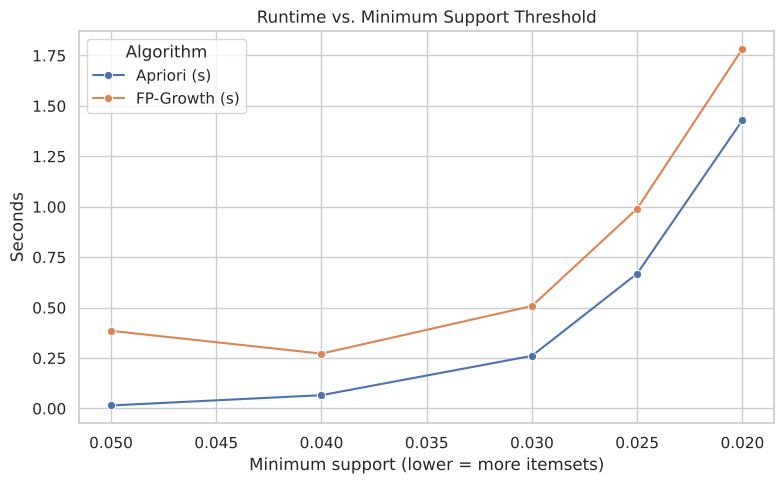

In [21]:
sweep_long = sweep.melt(id_vars=["min_support", "Itemsets"],
                        value_vars=["Apriori (s)", "FP-Growth (s)"],
                        var_name="Algorithm", value_name="Seconds")

plt.figure(figsize=(8, 5))
sns.lineplot(data=sweep_long, x="min_support", y="Seconds", hue="Algorithm", marker="o")
plt.gca().invert_xaxis()
plt.title("Runtime vs. Minimum Support Threshold")
plt.xlabel("Minimum support (lower = more itemsets)")
plt.ylabel("Seconds")
plt.tight_layout()
plt.show()

## Step 4: Generating and Analyzing Association Rules

I generate rules from the frequent itemsets of both algorithms. I use a **minimum confidence of 0.5**, so a rule only stays if at least 50% of the invoices that contain the antecedent also contain the consequent. The metrics I look at are:

- **Support**: how often the antecedent and consequent show up together in all invoices.
- **Confidence**: out of the invoices with the antecedent, the fraction that also have the consequent.
- **Lift**: how much more likely the consequent is when the antecedent is present compared to how common the consequent is overall. A lift above 1 means a positive association, and about 1 means the two are basically independent.

In [22]:
MIN_CONFIDENCE = 0.5

def make_rules(itemsets):
    # newer versions of mlxtend need the number of transactions, older ones do not
    try:
        return association_rules(itemsets, num_itemsets=len(basket),
                                 metric="confidence", min_threshold=MIN_CONFIDENCE)
    except TypeError:
        return association_rules(itemsets, metric="confidence", min_threshold=MIN_CONFIDENCE)

rules_apriori = make_rules(apriori_itemsets[["support", "itemsets"]])
rules_fp = make_rules(fp_itemsets[["support", "itemsets"]])

print("Rules from Apriori itemsets:  ", len(rules_apriori))
print("Rules from FP-Growth itemsets:", len(rules_fp))

Rules from Apriori itemsets:   75
Rules from FP-Growth itemsets: 75


In [23]:
def rule_key(df):
    return set(zip(df["antecedents"].apply(frozenset), df["consequents"].apply(frozenset)))

print("Both algorithms give the same rules:", rule_key(rules_apriori) == rule_key(rules_fp))

Both algorithms give the same rules: True


Since the itemsets are identical, the rules are identical too, so I use the FP-Growth rules for the rest of the analysis. I also convert the frozensets to readable text and sort by lift.

In [24]:
rules = rules_fp.copy()
rules["antecedents"] = rules["antecedents"].apply(lambda s: " + ".join(sorted(s)))
rules["consequents"] = rules["consequents"].apply(lambda s: " + ".join(sorted(s)))

cols = ["antecedents", "consequents", "support", "confidence", "lift"]
rules = rules.sort_values("lift", ascending=False).reset_index(drop=True)

print("Total rules:", len(rules))
print("Rules with lift > 1:", (rules["lift"] > 1).sum())
rules[cols].head(15).round(3)

Total rules: 75
Rules with lift > 1: 75


,antecedents,consequents,support,confidence,lift
0,WOODEN HEART CHRISTMAS SCANDINAVIAN,WOODEN STAR CHRISTMAS SCANDINAVIAN,0.021,0.723,27.019
1,WOODEN STAR CHRISTMAS SCANDINAVIAN,WOODEN HEART CHRISTMAS SCANDINAVIAN,0.021,0.768,27.019
2,GREEN REGENCY TEACUP AND SAUCER + ROSES REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,0.027,0.703,17.923
3,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER + ROSES REGENCY TEACUP AND SAUCER,0.027,0.701,17.923
4,PINK REGENCY TEACUP AND SAUCER + ROSES REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.027,0.903,17.339
5,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER + ROSES REGENCY TEACUP AND SAUCER,0.027,0.528,17.339
6,GREEN REGENCY TEACUP AND SAUCER + PINK REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,0.027,0.854,15.994
7,ROSES REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER + PINK REGENCY TEACUP AND SAUCER,0.027,0.515,15.994
8,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.032,0.821,15.760
9,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,0.032,0.618,15.760


**Top rules by confidence:**

In [25]:
rules.sort_values("confidence", ascending=False)[cols].head(10).round(3)

,antecedents,consequents,support,confidence,lift
4,PINK REGENCY TEACUP AND SAUCER + ROSES REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.027,0.903,17.339
6,GREEN REGENCY TEACUP AND SAUCER + PINK REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,0.027,0.854,15.994
8,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.032,0.821,15.760
54,JUMBO BAG PINK POLKADOT + JUMBO SHOPPER VINTAGE RED PAISLEY,JUMBO BAG RED RETROSPOT,0.020,0.806,7.458
55,JUMBO BAG PINK POLKADOT + JUMBO STORAGE BAG SUKI,JUMBO BAG RED RETROSPOT,0.023,0.802,7.419
13,GREEN REGENCY TEACUP AND SAUCER + REGENCY CAKESTAND 3 TIER,ROSES REGENCY TEACUP AND SAUCER,0.020,0.791,14.807
12,REGENCY CAKESTAND 3 TIER + ROSES REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.020,0.791,15.188
17,PINK REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,0.030,0.776,14.537
1,WOODEN STAR CHRISTMAS SCANDINAVIAN,WOODEN HEART CHRISTMAS SCANDINAVIAN,0.021,0.768,27.019
25,GREEN REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,0.039,0.751,14.064


### 4.1 Visualizing the rules

**Confidence vs. lift.** Every point is one rule. Points in the upper right (high confidence and high lift) are the strongest, most useful rules. The color shows the support of the rule.

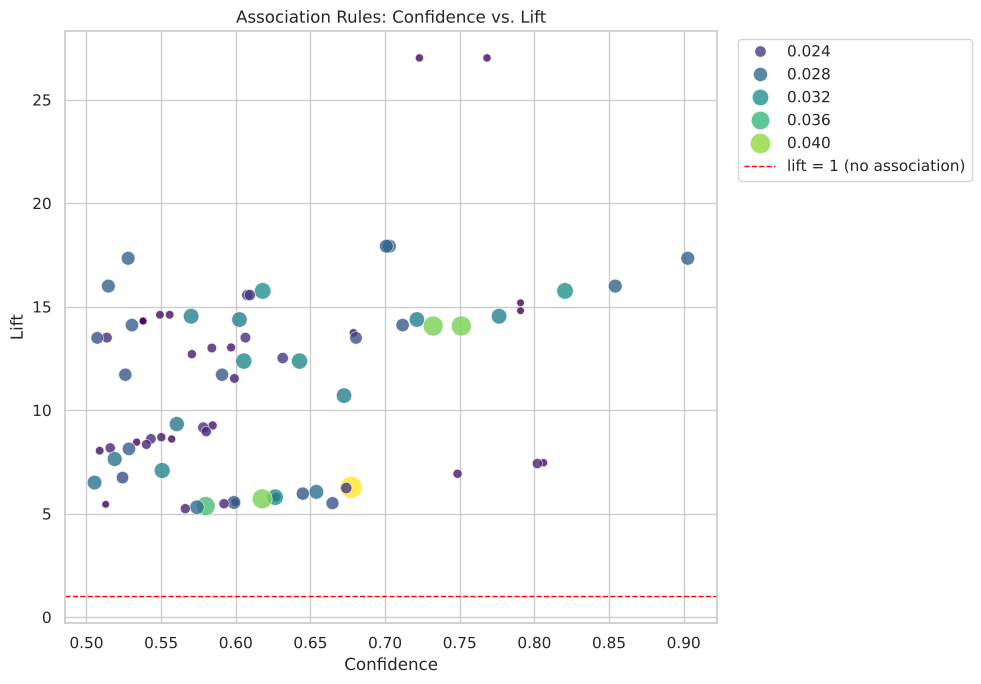

In [26]:
plt.figure(figsize=(10, 7))
sns.scatterplot(data=rules, x="confidence", y="lift", hue="support",
                size="support", sizes=(30, 250), palette="viridis", alpha=0.8)
plt.axhline(1, color="red", linestyle="--", linewidth=1, label="lift = 1 (no association)")
plt.title("Association Rules: Confidence vs. Lift")
plt.xlabel("Confidence")
plt.ylabel("Lift")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Support vs. confidence.** This shows whether the rules that are common (high support) are also reliable (high confidence).

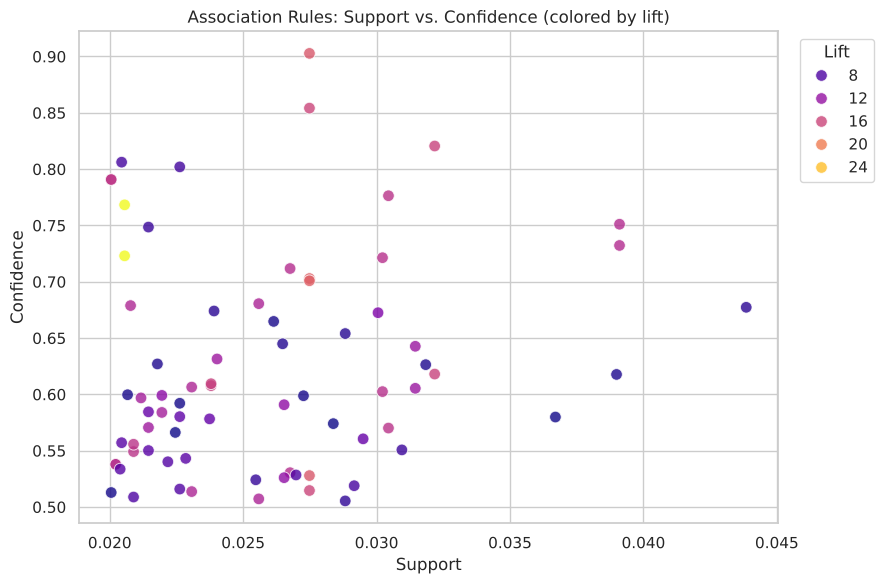

In [27]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=rules, x="support", y="confidence", hue="lift",
                palette="plasma", alpha=0.8, s=70)
plt.title("Association Rules: Support vs. Confidence (colored by lift)")
plt.xlabel("Support")
plt.ylabel("Confidence")
plt.legend(title="Lift", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Top 10 rules by lift.**

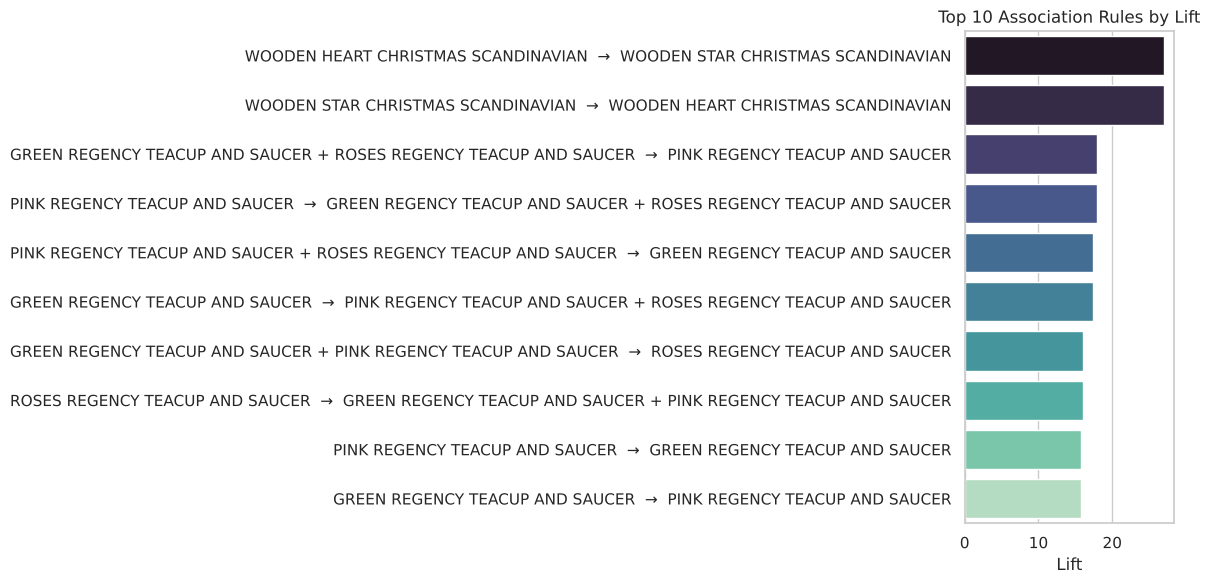

In [28]:
top_rules = rules.head(10).copy()
top_rules["rule"] = top_rules["antecedents"] + "  →  " + top_rules["consequents"]

plt.figure(figsize=(12, 6))
sns.barplot(data=top_rules, y="rule", x="lift", hue="rule", palette="mako", legend=False)
plt.title("Top 10 Association Rules by Lift")
plt.xlabel("Lift")
plt.ylabel("")
plt.tight_layout()
plt.show()

**Lift heatmap for single-item rules.** For rules with exactly one item on each side, I make a matrix of the lift values so I can see which product pairs are strongly linked.

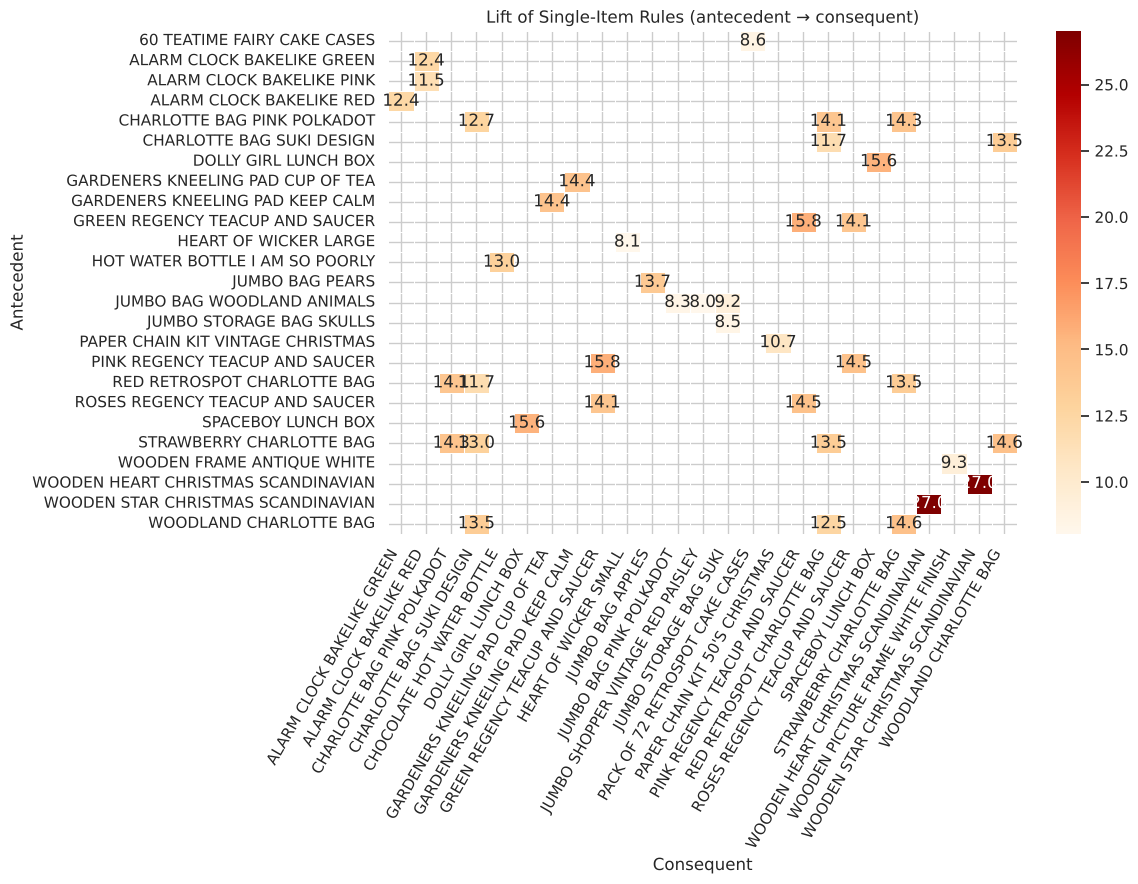

In [29]:
single = rules[~rules["antecedents"].str.contains(r" \+ ") & ~rules["consequents"].str.contains(r" \+ ")]
top_single = single.head(40)

if len(top_single) > 1:
    pivot = top_single.pivot_table(index="antecedents", columns="consequents", values="lift")
    plt.figure(figsize=(12, 9))
    sns.heatmap(pivot, annot=True, fmt=".1f", cmap="OrRd", linewidths=0.5)
    plt.title("Lift of Single-Item Rules (antecedent → consequent)")
    plt.xlabel("Consequent")
    plt.ylabel("Antecedent")
    plt.xticks(rotation=60, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough single-item rules to draw a heatmap.")

### 4.2 Interpreting the rules

In [30]:
best = rules.iloc[0]
print("Strongest rule by lift:")
print(f"  If a customer buys: {best['antecedents']}")
print(f"  They also buy:      {best['consequents']}")
print(f"  support = {best['support']:.3f}, confidence = {best['confidence']:.3f}, lift = {best['lift']:.1f}")
print()
print(f"Median lift across all rules: {rules['lift'].median():.1f}")
print(f"Median confidence across all rules: {rules['confidence'].median():.2f}")
print(f"Highest support among the rules: {rules['support'].max():.3f}")

Strongest rule by lift:
  If a customer buys: WOODEN HEART CHRISTMAS SCANDINAVIAN
  They also buy:      WOODEN STAR CHRISTMAS SCANDINAVIAN
  support = 0.021, confidence = 0.723, lift = 27.0

Median lift across all rules: 11.7
Median confidence across all rules: 0.60
Highest support among the rules: 0.044


**My interpretation:**

- All 75 rules have a lift above 1, and the median lift is about 11.7, so these items are bought together far more often than chance would suggest. That tells me the rules are not just reflecting the fact that a few products are popular.
- The strongest rule by lift is **Wooden Heart Christmas Scandinavian → Wooden Star Christmas Scandinavian** (support 0.021, confidence 0.72, lift 27.0). Both are items from the same Christmas decoration range, so it makes sense that people buy them together.
- The biggest group of rules is about the **Regency teacup and saucer** range. The green, pink, and roses versions are bought together very often. For example, pink + roses → green has a confidence of about 0.90 and a lift of about 17. Customers seem to buy the different colors as a set.
- The jumbo bag rules (for example, Jumbo Bag Pink Polkadot + Jumbo Storage Bag Suki → Jumbo Bag Red Retrospot) have a confidence of about 0.80 but a lower lift of about 7.4. The Red Retrospot bag is a very popular item on its own, so a good part of that confidence comes from its popularity. This is why I looked at lift and not only at confidence.
- Rules come in pairs (A → B and B → A) with the same support and lift but different confidence. The confidence is higher in the direction where the antecedent is the rarer item.
- Support values are small (the highest is about 0.044) because there are thousands of different products, so even the best item combinations show up in only a few percent of invoices.

**How a business could use these:** The shop could show "customers also bought" suggestions, sell the teacup colors or the wooden Christmas decorations as bundles, and keep the linked items in stock at the same time.

One limit I want to point out: the rules only show that items are bought together, not that one causes the other, and they are only based on UK invoices from December 2010 to December 2011.

## Step 5: Comparative Analysis

### Apriori vs. FP-Growth results

In [31]:
summary = pd.DataFrame({
    "Metric": ["Frequent itemsets found", "Association rules (conf ≥ 0.5)",
               "Average runtime (s)", "Identical output?"],
    "Apriori": [len(apriori_itemsets), len(rules_apriori), round(np.mean(apriori_times), 3), "Yes" if a == f else "No"],
    "FP-Growth": [len(fp_itemsets), len(rules_fp), round(np.mean(fp_times), 3), "Yes" if a == f else "No"],
})
summary

,Metric,Apriori,FP-Growth
0,Frequent itemsets found,399,399
1,Association rules (conf ≥ 0.5),75,75
2,Average runtime (s),1.313,1.835
3,Identical output?,Yes,Yes


**Output:** Both algorithms found exactly the same frequent itemsets, with the same support values, and so the same association rules. This is what I expected, since both are exact algorithms and only differ in the way they search for itemsets.

**Speed:** On my run, **Apriori was faster than FP-Growth**. At the main threshold of 0.02 Apriori averaged about 1.3 seconds and FP-Growth about 1.8 seconds, so Apriori was about 1.4x faster. In the support sweep Apriori was also faster at every threshold I tried (0.05, 0.04, 0.03, 0.025, and 0.02), although the gap got smaller as the threshold went down. At 0.05 Apriori took almost no time and FP-Growth took longer, but at 0.02 the two were fairly close.

This is the opposite of what the theory says, so I thought about why:
- **Apriori** builds candidate itemsets level by level and rescans the data to count them. That is normally slow when there are a lot of candidates. But after I removed items below the support threshold, only 300 items were left, and the frequent itemsets are small (300 single items, 94 pairs, and only 5 triples). So there were very few levels and not many candidates, and the mlxtend version of Apriori does the counting with fast NumPy operations.
- **FP-Growth** builds an FP-tree and mines it without generating candidates. That is an advantage when there are many items and long itemsets, but here the tree-building and the recursive mining have an overhead that is not paid back, since the itemsets are short and the data is small after pruning.
- The gap getting smaller as the support gets lower matches the theory. FP-Growth's advantage should grow when the threshold is lowered further and the itemsets get longer. I could not test that because Apriori ran out of memory on my computer at a support of 0.015.

So for this dataset and these thresholds Apriori was the faster choice, but I would still expect FP-Growth to scale better on bigger data or much lower thresholds. The timings also depend on the mlxtend implementations and my computer, not only on the algorithms.

### Challenges I faced and how I handled them

1. **Dataset cleaning.** The raw data has cancelled invoices, negative quantities, missing descriptions, and non-product rows like postage and bank charges. I filtered those out, because otherwise they would show up as "frequent items" and produce rules that don't mean anything.
2. **Size of the data.** Turning the whole dataset into a one-hot basket matrix with thousands of item columns is heavy on memory. I kept only United Kingdom invoices, used the `bool` data type for the matrix, and made sure each item only counts once per invoice. My first version of the basket matrix used `pivot_table`, which crashed the kernel from memory use, so I switched to filling a NumPy True/False array directly from numeric codes. Apriori also used a lot of memory on the full matrix, so before mining I dropped items that appear in fewer invoices than the support threshold, since they can't be in any frequent itemset anyway.
3. **Choosing the support threshold.** A high threshold gave almost no itemsets, and a very low one made Apriori slow. I tested a few values and settled on 0.02, which gave 399 itemsets and 75 rules, enough to analyze while still running in a reasonable time. A threshold of 0.015 made Apriori run out of memory on my computer, so the support sweep stops at 0.02.
4. **mlxtend version differences.** `association_rules` takes slightly different arguments in newer versions of the library, so I wrapped it in a small function that works with both.
5. **Reading the results.** The itemsets and rules come back as frozensets, which are hard to read and to plot. I converted them into text labels. I also learned that high confidence alone can be misleading when the consequent is a very popular item, so I used lift to judge how strong the rules really are.

### Conclusion

Association rule mining was a good way to find which products are bought together in real transaction data, and lift turned out to be the most useful metric for separating meaningful rules from ones that only reflect popular items. Apriori and FP-Growth gave exactly the same itemsets and rules. On my data Apriori was actually the faster one, because pruning left only a small number of items and short itemsets, but FP-Growth should be the better choice as the data or the number of frequent itemsets grows.